# Exercise: Can an encoder find malaria?

Each image is one blood cell. Some cells are **parasitized** (infected with malaria). Some are **uninfected**.

We used a pretrained encoder (DINOv2) to turn each image into a row of 768 numbers.

## Setup

In [1]:
library('tidymodels')
library('embed')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──


✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 


── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/


## 1. Load the data

Here are 6 example cells. The top row is parasitized. The bottom row is uninfected.

<img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C129P90ThinF_IMG_20151004_133921_cell_105.png" width="90"><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C189P150ThinF_IMG_20151203_140809_cell_133.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C52P13thinF_IMG_20150725_130013_cell_194.png" width="90"> <br><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C147P108ThinF_IMG_20151115_101156_cell_82.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C184P145ThinF_IMG_20151203_102405_cell_137.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C77P38ThinF_IMG_20150601_152941_cell_55.png" width="90">

The encoder already ran. Each row of `malaria` is one image. `e1` to `e768` are its embedding.

In [2]:
malaria <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_embeddings.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

malaria |> select(id, label, e1:e5) |> head()

 [0%] Downloaded 16375 bytes...

 [1%] Downloaded 32750 bytes...

 [1%] Downloaded 49125 bytes...

 [2%] Downloaded 65500 bytes...

 [2%] Downloaded 65536 bytes...

 [2%] Downloaded 81911 bytes...

... (176 outputs left out)

 [98%] Downloaded 2980261 bytes...

 [99%] Downloaded 2996663 bytes...

 [100%] Downloaded 3010429 bytes...

  id                                         label      e1     e2      e3    
1 C184P145ThinF_IMG_20151203_102405_cell_137 uninfected 0.0045  0.0178 0.0393
2 C77P38ThinF_IMG_20150601_152941_cell_55    uninfected 0.0321 -0.0049 0.0702
3 C147P108ThinF_IMG_20151115_101156_cell_82  uninfected 0.0174 -0.0118 0.0692
4 C223ThinF_IMG_20151112_104410_cell_156     uninfected 0.0114 -0.0091 0.0375
5 C92P53ThinF_IMG_20150821_151646_cell_32    uninfected 0.0226  0.0284 0.0138
6 C83P44ThinF_IMG_20150817_134331_cell_194   uninfected 0.0194 -0.0292 0.0345
  e4      e5     
1 -0.0475  0.0563
2 -0.0556 -0.0220
3 -0.0476 -0.0041
4 -0.0590  0.0046
5 -0.0545  0.0345
6 -0.0767  0.0011

In [3]:
malaria |> count(label)

  label       n   
1 uninfected  1000
2 parasitized 1000

## 2. Visualize with UMAP

We cannot plot 768 dimensions at once. **UMAP** squeezes all the dimensions into 2 new columns, `UMAP1` and `UMAP2`. Similar images wil have similar `UMAP1` and `UMAP2` values.

Run the cell. It makes the 2 UMAP columns. (It takes a few seconds.)

In [4]:
set.seed(1)

umap_coords <- recipe(label ~ ., data = select(malaria, -id)) |>
    step_umap(all_predictors(), num_comp = 2) |>
    prep() |>
    bake(new_data = NULL)

umap_coords |> head()

  label      UMAP1     UMAP2     
1 uninfected -3.885077 -0.1045645
2 uninfected -2.033472  1.3991832
3 uninfected -2.757028 -0.8090479
4 uninfected -4.483551 -0.1679591
5 uninfected -2.477914  4.1084366
6 uninfected -2.114880  2.5737996

**Your turn:** plot `UMAP1` against `UMAP2`. Color the points by `label`.

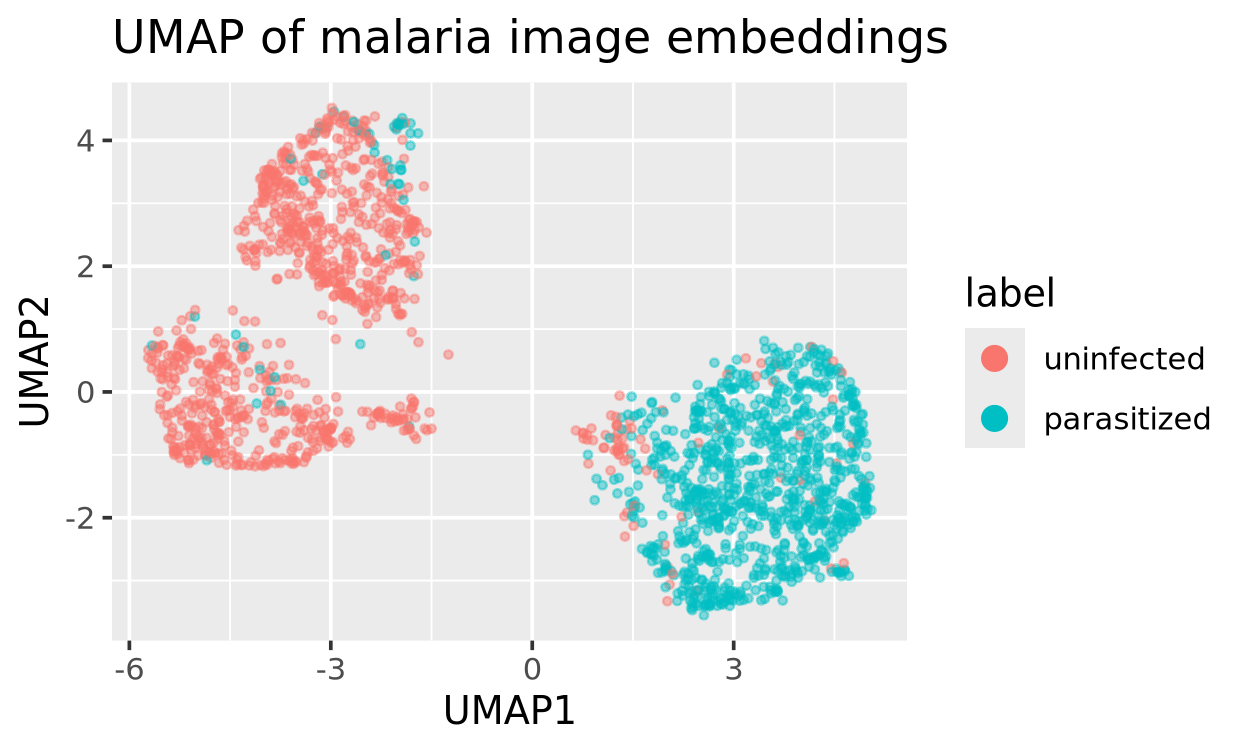

In [5]:
ggplot(umap_coords, aes(x = UMAP1, y = UMAP2, color = label)) +
    geom_point(alpha = 0.45, size = 0.8) +
    labs(title = 'UMAP of malaria image embeddings', x = 'UMAP1', y = 'UMAP2') +
    guides(color = guide_legend(override.aes = list(alpha = 1, size = 3)))


**Check:** do the two kinds of cell land in different places?

- **Answer:** The UMAP plot shows clear but not perfectly separate groups. There is substantial separation overall, with some overlap near the boundary.
- Cells near the overlap between the red and blue groups are hardest to distinguish.


## 3. Split the data

Run this cell. Do not change it.

- `train`: half of the images. The model learns from these.
- `test`: the other half. The model has never seen these. We measure accuracy here.

In [6]:
set.seed(512)

split <- initial_split(malaria, prop = 0.5, strata = label)
train <- training(split) |> select(-id)
test  <- testing(split)  |> select(-id)

nrow(train)

[1] 1000

## 4. Pick a model

Pick a classifier model that we've worked with before (e.g. random forest). Fit it on `train`. Find the accuracy on `test`.

Options:

- `logistic_reg(penalty = 0.01, mixture = 0) |> set_engine('glmnet')`: logistic regression. We have 768 columns, so it needs a `penalty` (like in lecture 16).
- `rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')`: random forest.
- `mlp(hidden_units = 10, epochs = 500) |> set_mode('classification') |> set_engine('nnet', MaxNWts = 10000)`: neural net.

Use the formula `label ~ .` (all other embeddings columns are predictors).

In [7]:
set.seed(512)

fit <- logistic_reg(penalty = 0.01, mixture = 0) |>
    set_engine('glmnet') |>
    fit(label ~ ., data = train)

fit


parsnip model object


Call:  glmnet::glmnet(x = maybe_matrix(x), y = y, family = "binomial",      alpha = 0) 

     Df  %Dev Lambda
1   768  0.00 407.40
2   768  9.75 371.20
3   768 10.60 338.30
4   768 11.47 308.20
5   768 12.40 280.80
6   768 13.39 255.90
7   768 14.43 233.10
8   768 15.54 212.40
9   768 16.70 193.60
10  768 17.93 176.40
11  768 19.21 160.70
12  768 20.55 146.40
13  768 21.94 133.40
14  768 23.39 121.60
15  768 24.88 110.80
16  768 26.41 100.90
17  768 27.99  91.96
18  768 29.60  83.79
19  768 31.23  76.34
20  768 32.89  69.56
21  768 34.30  63.38
22  768 35.97  57.75
23  768 37.65  52.62
24  768 39.33  47.95
25  768 41.01  43.69
26  768 42.67  39.81
27  768 44.32  36.27
28  768 45.95  33.05
29  768 47.56  30.11
30  768 49.13  27.44
31  768 50.68  25.00
32  768 52.20  22.78
33  768 53.68  20.76
34  768 55.12  18.91
35  768 56.52  17.23
36  768 57.89  15.70
37  768 59.21  14.31
38  768 60.49  13.03
39  768 61.73  11.88
40  768 62.93  10.82
41  768 64.08   9.86
42  76

<details>
<summary>Hint: how do I find the accuracy?</summary>

1. `predict()` gives the predicted class for each test image.
2. `bind_cols()` puts it next to the true `label`.
3. `accuracy()` compares them.

```r
predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)
```

Here `fit` is the name of your fitted model. Use your own name.

</details>

In [8]:
test_accuracy <- predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)

train_accuracy <- predict(fit, new_data = train) |>
    bind_cols(train) |>
    accuracy(truth = label, estimate = .pred_class)

bind_rows(
    train_accuracy |> mutate(set = 'train'),
    test_accuracy |> mutate(set = 'test')
)


  .metric  .estimator .estimate set  
1 accuracy binary     0.993     train
2 accuracy binary     0.953     test 

**Check:** a good model gets about 0.93 to 0.95 on the test images.

- I picked penalized logistic regression because it is a regularized linear model suited to 768 embedding columns and tends to avoid fitting the many dimensions too strongly.
- Training accuracy is 0.993 and test accuracy is 0.953. Train is about 4 percentage points higher, which suggests modest overfitting but strong generalization.


## 5. Bonus: raw pixels

We also have the raw pixels for the same cells: `malaria_pixels.csv.gz`. That is 32 x 32 = 1,024 columns named `p1` to `p1024`.

Use the same split. Fit the same kind of model on the pixels. How does the test accuracy compare to the embeddings?

In [9]:
pixels <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_pixels.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

train_pix <- pixels |> filter(id %in% training(split)$id) |> select(-id)
test_pix  <- pixels |> filter(id %in% testing(split)$id)  |> select(-id)

set.seed(512)
fit_pix <- logistic_reg(penalty = 0.01, mixture = 0) |>
    set_engine('glmnet') |>
    fit(label ~ ., data = train_pix)

predict(fit_pix, new_data = test_pix) |>
    bind_cols(test_pix) |>
    accuracy(truth = label, estimate = .pred_class)


 [1%] Downloaded 16375 bytes...

 [2%] Downloaded 32759 bytes...

 [3%] Downloaded 49134 bytes...

 [4%] Downloaded 65527 bytes...

 [5%] Downloaded 81902 bytes...

 [6%] Downloaded 98295 bytes...

... (85 outputs left out)

 [98%] Downloaded 1539895 bytes...

 [99%] Downloaded 1556270 bytes...

 [100%] Downloaded 1556446 bytes...

  .metric  .estimator .estimate
1 accuracy binary     0.639    

*Your answer:* Embeddings are better for finding malaria. The embedding model gets about 0.953 test accuracy, while raw pixels get about 0.639. The pretrained encoder condenses 768 semantically useful image features, while the raw pixel model must learn the full 32 × 32 pattern directly and overfits or misses biologically meaningful structure.
